# Example 13.1: Surrogate Neural Network for Forward Kinematics
**Chapter 13 – Neural Networks for Four-Bar Linkage Mechanism Synthesis**

Train a 5→32→32→2 MLP to predict the coupler position (x_P, y_P).

Samples generated: 2000
Epoch  50  MSE_tr=0.04491  MSE_val=0.04469
Epoch 100  MSE_tr=0.03643  MSE_val=0.03773
Epoch 150  MSE_tr=0.03301  MSE_val=0.03497
Epoch 200  MSE_tr=0.03078  MSE_val=0.03299
Epoch 250  MSE_tr=0.02902  MSE_val=0.03135
Epoch 300  MSE_tr=0.02757  MSE_val=0.02993

Validation RMSE (norm.): 0.17301
Validation RMSE (mm):    34.60 mm


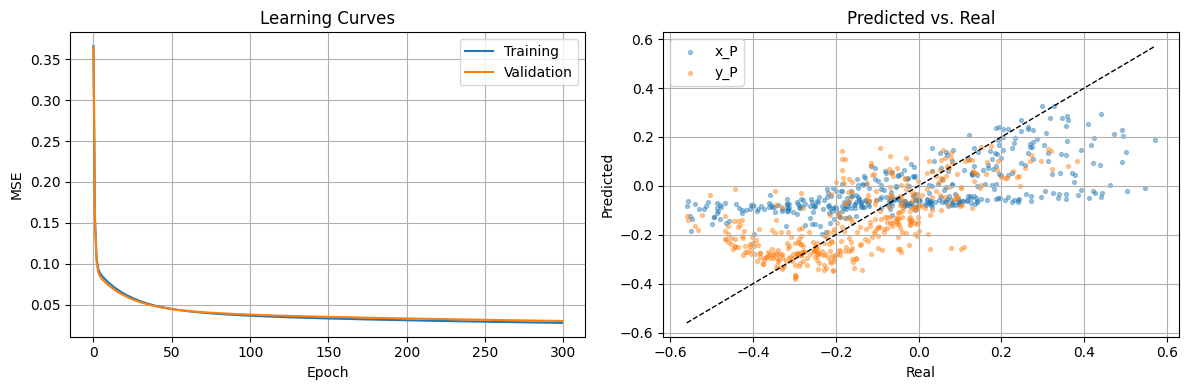

Figure saved: surrogate_learning.png


In [3]:
from numpy import *
import matplotlib.pyplot as plt

random.seed(42)

def theta3(a, b, c, d, th2):
    x2 = a*cos(th2)-d; y2 = a*sin(th2)
    r  = sqrt(x2**2+y2**2)
    arg= clip((r**2+c**2-b**2)/(2*r*c), -1., 1.)
    return arctan2(y2, x2) + arccos(arg)

def acoplador_xy(a, b, c, d, th2, lp=40., delta=pi/6):
    t3 = theta3(a, b, c, d, th2)
    return a*cos(th2)+lp*cos(t3+delta), a*sin(th2)+lp*sin(t3+delta)

# Generate data
N=2000; X_list, Y_list = [], []
it=0
while len(X_list)<N and it<60000:
    it+=1
    a=random.uniform(20,80); b=random.uniform(40,120)
    c=random.uniform(40,120); d=85.
    s=sorted([a,b,c,d])
    if s[0]+s[3]>s[1]+s[2]: continue
    th2=random.uniform(0,2*pi)
    xP,yP=acoplador_xy(a,b,c,d,th2)
    if isnan(xP): continue
    X_list.append([a/120,b/120,c/120,d/120,th2/(2*pi)])
    Y_list.append([xP/200, yP/200])

X=array(X_list); Y=array(Y_list)
print(f"Samples generated: {len(X)}")

perm=random.permutation(len(X)); ntr=int(0.8*len(X))
Xtr,Ytr=X[perm[:ntr]],Y[perm[:ntr]]
Xv,Yv=X[perm[ntr:]],Y[perm[ntr:]]

def relu(z): return maximum(0,z)
W1=random.randn(5,32)*sqrt(2/5); b1=zeros((1,32))
W2=random.randn(32,32)*sqrt(2/32); b2=zeros((1,32))
W3=random.randn(32,2)*sqrt(2/32);  b3=zeros((1,2))
LR,BS,LAM=1e-3,64,1e-4
hist_tr, hist_val=[],[]

for ep in range(300):
    perm2=random.permutation(ntr)
    for s in range(0,ntr,BS):
        ib=perm2[s:s+BS]; xb,yb=Xtr[ib],Ytr[ib]
        Z1=xb@W1+b1; A1=relu(Z1); Z2=A1@W2+b2; A2=relu(Z2); yh=A2@W3+b3
        n=len(xb); dZ3=(yh-yb)/n
        dW3=A2.T@dZ3; db3=dZ3.sum(0,keepdims=True)
        dA2=dZ3@W3.T; dZ2=dA2*(Z2>0)
        dW2=A1.T@dZ2; db2=dZ2.sum(0,keepdims=True)
        dA1=dZ2@W2.T; dZ1=dA1*(Z1>0)
        dW1=xb.T@dZ1; db1g=dZ1.sum(0,keepdims=True)
        W1-=LR*(dW1+LAM*W1); b1-=LR*db1g
        W2-=LR*(dW2+LAM*W2); b2-=LR*db2
        W3-=LR*(dW3+LAM*W3); b3-=LR*db3
    def fwd(Xd):
        return relu(relu(Xd@W1+b1)@W2+b2)@W3+b3
    hist_tr.append(mean((fwd(Xtr)-Ytr)**2))
    hist_val.append(mean((fwd(Xv)-Yv)**2))
    if (ep+1)%50==0:
        print(f"Epoch {ep+1:3d}  MSE_tr={hist_tr[-1]:.5f}  MSE_val={hist_val[-1]:.5f}")

rmse=sqrt(hist_val[-1])
print(f"\nValidation RMSE (norm.): {rmse:.5f}")
print(f"Validation RMSE (mm):    {rmse*200:.2f} mm")

# Plotting
fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].plot(hist_tr, label='Training'); axes[0].plot(hist_val, label='Validation')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE')
axes[0].set_title('Learning Curves'); axes[0].legend(); axes[0].grid(True)
Yhat=fwd(Xv)
axes[1].scatter(Yv[:,0], Yhat[:,0], alpha=0.4, s=8, label='x_P')
axes[1].scatter(Yv[:,1], Yhat[:,1], alpha=0.4, s=8, label='y_P')
mn,mx=Yv.min(),Yv.max()
axes[1].plot([mn,mx],[mn,mx],'k--',lw=1)
axes[1].set_xlabel('Real'); axes[1].set_ylabel('Predicted')
axes[1].set_title('Predicted vs. Real'); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.savefig('surrogate_learning.png', dpi=150); plt.show()
print("Figure saved: surrogate_learning.png")